# Clasificación de Conexiones de Red con el Dataset NSL-KDD 

## A. Presentación y Descripción del Problema 

* **Dataset elegido:** NSL-KDD (*Network Security Laboratory - Knowledge Discovery in Databases*), versión depurada de KDD Cup '99 que elimina registros redundantes para evitar sesgos en modelos de aprendizaje automático.
* **Fuente:** OpenML (`fetch_openml("NSL-KDD")`) / *Canadian Institute for Cybersecurity* (UNB).
* **Tipo de problema:** Clasificación multiclase supervisada.
* **Objetivo:** Clasificar cada conexión de red en **5 categorías principales** —tráfico legítimo (**Normal**) y cuatro familias de ciberataques (**DoS**, **Probe**, **R2L**, **U2R**)— a partir de variables de conexión básica, contenido de sesión y estadísticas de tráfico en ventanas temporales y de host.

## B. Carga y Análisis Exploratorio de Datos (EDA) 

### B.1 Carga del dataset y agrupación de clases

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml

plt.style.use("seaborn-v0_8-whitegrid")

columnas_nsl = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
    "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login",
    "is_guest_login", "count", "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
    "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "class", "difficulty_level"
]

try:
    datos = fetch_openml("NSL-KDD", as_frame=True, parser="auto")
    df = datos.frame.copy()
    if "difficulty_level" in df.columns:
        df = df.drop(columns=["difficulty_level"])
except Exception:
    url_train = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt"
    url_test = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt"
    df_train_raw = pd.read_csv(url_train, names=columnas_nsl)
    df_test_raw = pd.read_csv(url_test, names=columnas_nsl)
    df = pd.concat([df_train_raw, df_test_raw], ignore_index=True).drop(columns=["difficulty_level"])

mapeo_ataques = {
    "normal": "Normal",
    # DoS
    "back": "DoS", "land": "DoS", "neptune": "DoS", "pod": "DoS",
    "smurf": "DoS", "teardrop": "DoS", "mailbomb": "DoS", "apache2": "DoS",
    "processtable": "DoS", "udpstorm": "DoS",
    # Probe
    "ipsweep": "Probe", "nmap": "Probe", "portsweep": "Probe",
    "satan": "Probe", "mscan": "Probe", "saint": "Probe",
    # R2L
    "ftp_write": "R2L", "guess_passwd": "R2L", "imap": "R2L",
    "multihop": "R2L", "phf": "R2L", "spy": "R2L", "warezclient": "R2L",
    "warezmaster": "R2L", "sendmail": "R2L", "named": "R2L",
    "snmpgetattack": "R2L", "snmpguess": "R2L", "xlock": "R2L",
    "xsnoop": "R2L", "worm": "R2L",
    # U2R
    "buffer_overflow": "U2R", "loadmodule": "U2R", "perl": "U2R",
    "rootkit": "U2R", "httptunnel": "U2R", "ps": "U2R",
    "sqlattack": "U2R", "xterm": "U2R"
}

df["class"] = df["class"].astype(str).str.strip().str.rstrip(".").map(mapeo_ataques)
df = df.dropna(subset=["class"]).reset_index(drop=True)

print("Dataset cargado:", df.shape)

Dataset cargado: (148517, 42)


### B.2 Vista general, tipos de datos, nulos y duplicados 

In [2]:
print("Dimensiones (filas, columnas):", df.shape)
total_nulos = int(df.isna().sum().sum())
print(f"\nValores nulos por columna (total nulos en dataset = {total_nulos}):")
nulos = df.isna().sum()
print(nulos[nulos > 0] if (nulos > 0).any() else "Sin valores nulos en ninguna columna.")

duplicados = int(df.duplicated().sum())
print(f"\nFilas exactamente duplicadas: {duplicados} ({duplicados / len(df) * 100:.2f}%)")

print("\nResumen de tipos de datos:")
print(df.dtypes.value_counts())

display(df.head(5))

Dimensiones (filas, columnas): (148517, 42)

Valores nulos por columna (total nulos en dataset = 0):
Sin valores nulos en ninguna columna.

Filas exactamente duplicadas: 629 (0.42%)

Resumen de tipos de datos:
int64      23
float64    15
object      4
Name: count, dtype: int64


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,Normal
1,0,udp,other,SF,146,0,0,0,0,0,...,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,Normal
2,0,tcp,private,S0,0,0,0,0,0,0,...,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,DoS
3,0,tcp,http,SF,232,8153,0,0,0,0,...,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,Normal
4,0,tcp,http,SF,199,420,0,0,0,0,...,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,Normal


### B.3 Distribución de la variable objetivo (`class`) 

,conteo,porcentaje (%)
class,,
Normal,77054,51.88
DoS,53385,35.95
Probe,14077,9.48
R2L,3749,2.52
U2R,252,0.17


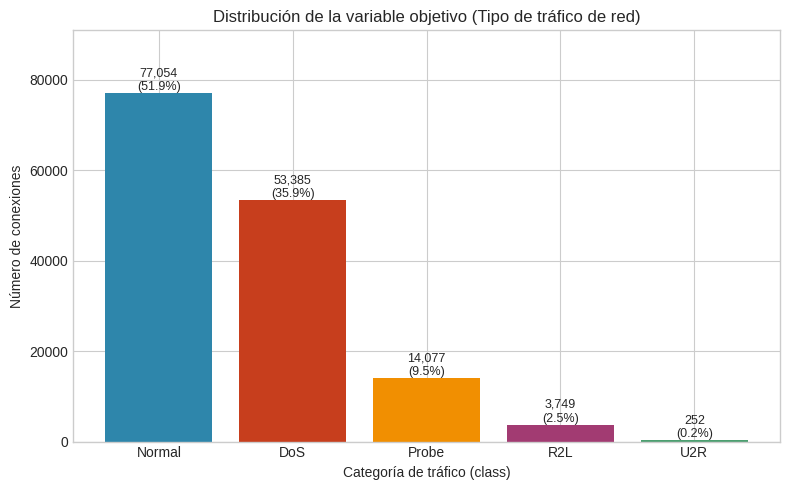

In [3]:
orden_clases = ["Normal", "DoS", "Probe", "R2L", "U2R"]
conteo = df["class"].value_counts().reindex(orden_clases).dropna().astype(int)
porcentaje = (conteo / len(df)) * 100

resumen_objetivo = pd.DataFrame({
    "conteo": conteo,
    "porcentaje (%)": porcentaje.round(2)
})
display(resumen_objetivo)

fig, ax = plt.subplots(figsize=(8, 5))
colores = ["#2E86AB", "#C73E1D", "#F18F01", "#A23B72", "#4C9F70"]
barras = ax.bar(conteo.index, conteo.values, color=colores)

for barra, n, p in zip(barras, conteo.values, porcentaje.values):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        f"{n:,}\n({p:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_title("Distribución de la variable objetivo (Tipo de tráfico de red)")
ax.set_xlabel("Categoría de tráfico (class)")
ax.set_ylabel("Número de conexiones")
ax.set_ylim(0, conteo.max() * 1.18)
plt.tight_layout()
plt.show()

### B.4 Variables categóricas y binarias / de conteo 

In [4]:
categoricas = ["protocol_type", "service", "flag"]
binarias = [
    "land", "wrong_fragment", "urgent", "hot",
    "num_failed_logins", "logged_in", "root_shell",
    "su_attempted", "num_compromised", "num_root",
    "num_file_creations", "num_shells", "num_access_files",
    "num_outbound_cmds", "is_host_login", "is_guest_login"
]

categoricas = [c for c in categoricas if c in df.columns]
binarias = [b for b in binarias if b in df.columns]

print("Variables categóricas:", len(categoricas), categoricas)
for c in categoricas:
    print(f"\n--- {c} (cardinalidad total: {df[c].nunique()}, top 10) ---")
    print(df[c].value_counts(dropna=False).head(10))

print("\nVariables de conteo/indicadores de acceso:", len(binarias))
for b in binarias:
    vals = df[b].value_counts().to_dict()
    top_vals = dict(list(vals.items())[:6])
    print(f"  {b} (únicos={len(vals)}): {top_vals}")

Variables categóricas: 3 ['protocol_type', 'service', 'flag']

--- protocol_type (cardinalidad total: 3, top 10) ---
protocol_type
tcp     121569
udp      17614
icmp      9334
Name: count, dtype: int64

--- service (cardinalidad total: 70, top 10) ---
service
http        48191
private     26627
domain_u     9937
smtp         8247
ftp_data     7711
other        5197
eco_i        4848
telnet       3979
ecr_i        3829
ftp          2446
Name: count, dtype: int64

--- flag (cardinalidad total: 11, top 10) ---
flag
SF        89820
S0        36864
REJ       15083
RSTR       3090
RSTO       2335
S1          386
SH          344
S3          298
S2          142
RSTOS0      105
Name: count, dtype: int64

Variables de conteo/indicadores de acceso: 16
  land (únicos=2): {0: 148485, 1: 32}
  wrong_fragment (únicos=3): {0: 147327, 3: 929, 1: 261}
  urgent (únicos=4): {0: 148498, 1: 10, 2: 7, 3: 2}
  hot (únicos=29): {0: 144839, 2: 1883, 1: 459, 28: 277, 30: 258, 4: 193}
  num_failed_logins (únicos=

### B.5 Variables numéricas (estadísticas descriptivas y asimetría) 

In [5]:
excluir = set(categoricas + binarias + ["class"])
numericas = [col for col in df.columns if col not in excluir and pd.api.types.is_numeric_dtype(df[col])]

print("Variables numéricas:", len(numericas))
display(df[numericas].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).round(2))

asimetria = df[numericas].skew().sort_values(ascending=False)
print("\nTop 10 variables numéricas con mayor asimetría:")
print(asimetria.head(10).round(2))

Variables numéricas: 22


,duration,src_bytes,dst_bytes,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
count,148517.00,1.485170e+05,1.485170e+05,148517.00,148517.00,148517.00,148517.00,148517.00,148517.00,148517.00,...,148517.00,148517.00,148517.00,148517.00,148517.00,148517.00,148517.00,148517.00,148517.00,148517.00
mean,276.78,4.022795e+04,1.708885e+04,83.34,28.25,0.26,0.26,0.14,0.14,0.67,...,183.93,119.46,0.53,0.08,0.15,0.03,0.26,0.25,0.14,0.14
std,2460.68,5.409612e+06,3.703525e+06,116.76,75.37,0.43,0.43,0.34,0.34,0.44,...,98.53,111.23,0.45,0.19,0.31,0.11,0.43,0.43,0.32,0.34
min,0.00,0.000000e+00,0.000000e+00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.000000e+00,0.000000e+00,2.00,2.00,0.00,0.00,0.00,0.00,0.10,...,87.00,11.00,0.05,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,0.00,4.400000e+01,0.000000e+00,13.00,7.00,0.00,0.00,0.00,0.00,1.00,...,255.00,72.00,0.60,0.02,0.00,0.00,0.00,0.00,0.00,0.00
75%,0.00,2.780000e+02,5.710000e+02,141.00,17.00,0.85,0.91,0.00,0.00,1.00,...,255.00,255.00,1.00,0.07,0.05,0.01,0.60,0.50,0.00,0.00
99%,8172.00,5.454000e+04,2.559816e+04,511.00,510.00,1.00,1.00,1.00,1.00,1.00,...,255.00,255.00,1.00,1.00,1.00,0.52,1.00,1.00,1.00,1.00
max,57715.00,1.379964e+09,1.309937e+09,511.00,511.00,1.00,1.00,1.00,1.00,1.00,...,255.00,255.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00



Top 10 variables numéricas con mayor asimetría:
dst_bytes                      314.94
src_bytes                      206.68
duration                        12.40
dst_host_srv_diff_host_rate      5.85
srv_count                        4.66
diff_srv_rate                    4.08
dst_host_diff_srv_rate           3.55
srv_diff_host_rate               2.85
dst_host_srv_rerror_rate         2.12
dst_host_rerror_rate             2.11
dtype: float64


### B.6 Gráficos exploratorios clave 📊

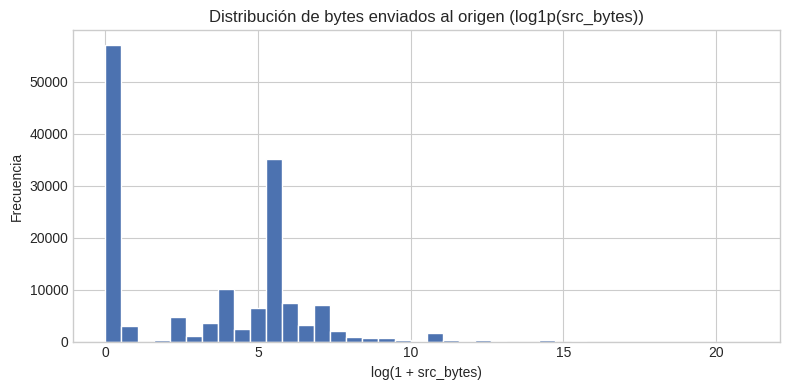


Tabla cruzada protocolo vs clase:


class,DoS,Normal,Probe,R2L,U2R
protocol_type,,,,,
icmp,3553,1402,4375,4,0
tcp,48926,61442,7721,3231,249
udp,906,14210,1981,514,3


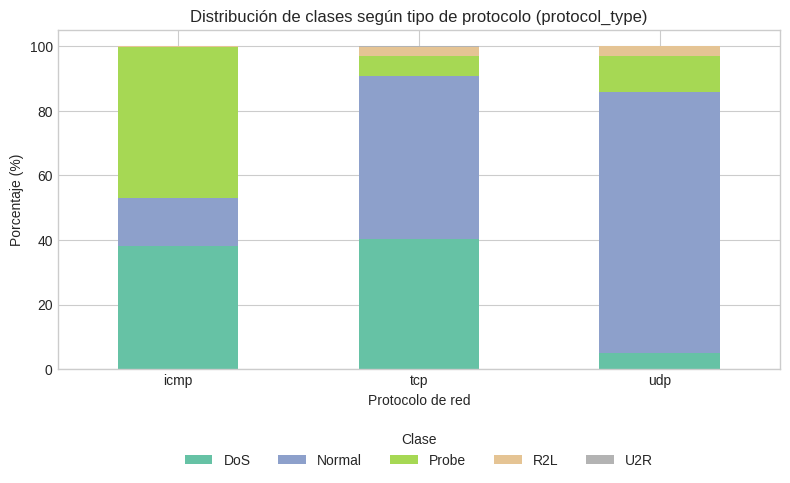

In [6]:
# B.6.1 Distribución de una variable numérica clave (con escala logarítmica)
fig, ax = plt.subplots(figsize=(8, 4))
valores_src = np.log1p(df["src_bytes"].clip(lower=0))
ax.hist(valores_src, bins=40, color="#4C72B0", edgecolor="white")
ax.set_title("Distribución de bytes enviados al origen (log1p(src_bytes))")
ax.set_xlabel("log(1 + src_bytes)")
ax.set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

# B.6.2 Relación entre variable categórica (protocol_type) y variable objetivo (class)
conteos_proto = pd.crosstab(df["protocol_type"], df["class"])
print("\nTabla cruzada protocolo vs clase:")
display(conteos_proto)

porcentajes_proto = pd.crosstab(df["protocol_type"], df["class"], normalize="index") * 100
ax = porcentajes_proto.plot(kind="bar", stacked=True, figsize=(8, 5), colormap="Set2")
ax.set_title("Distribución de clases según tipo de protocolo (protocol_type)")
ax.set_xlabel("Protocolo de red")
ax.set_ylabel("Porcentaje (%)")
ax.legend(title="Clase", loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=5)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### B.7 Matriz de correlación en variables numéricas 

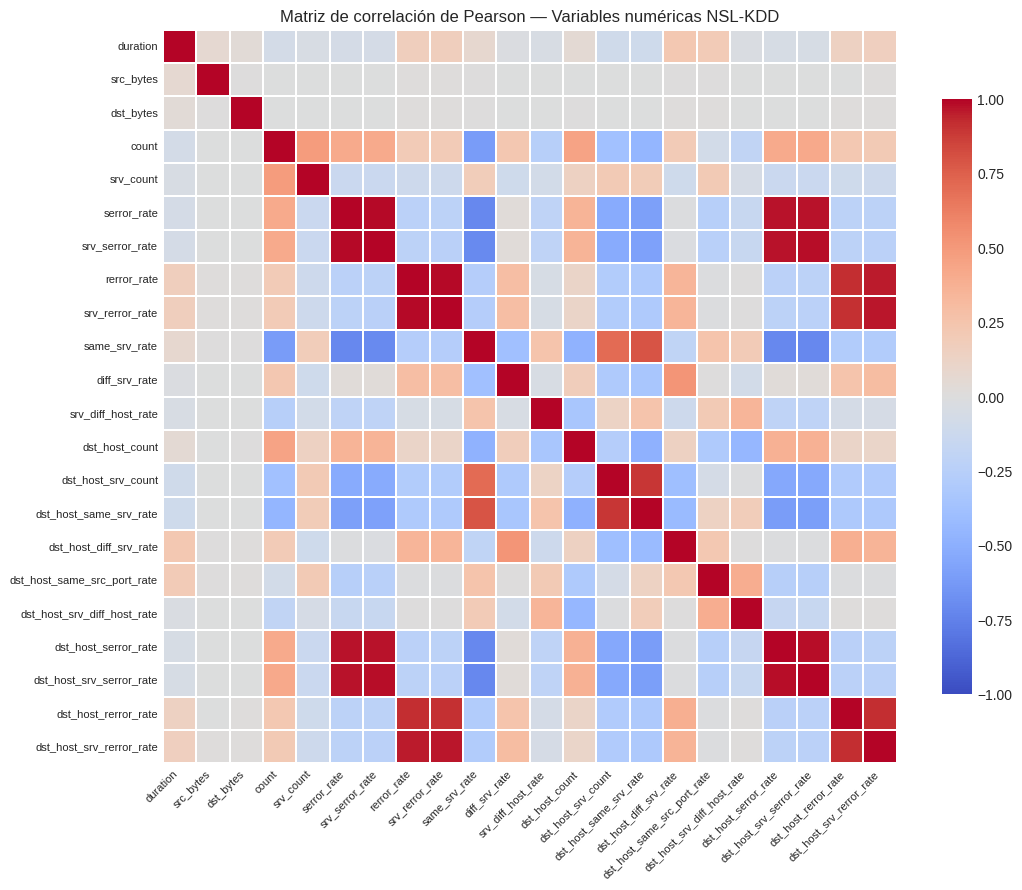

Top 10 pares de variables numéricas por correlación absoluta:
srv_serror_rate           serror_rate             0.992
srv_rerror_rate           rerror_rate             0.986
dst_host_srv_serror_rate  dst_host_serror_rate    0.983
                          srv_serror_rate         0.982
                          serror_rate             0.976
dst_host_serror_rate      serror_rate             0.975
                          srv_serror_rate         0.971
dst_host_srv_rerror_rate  srv_rerror_rate         0.966
                          rerror_rate             0.957
                          dst_host_rerror_rate    0.921
dtype: float64


In [7]:
corr_matrix = df[numericas].corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.3,
    cbar_kws={"shrink": 0.8},
    ax=ax
)
ax.set_title("Matriz de correlación de Pearson — Variables numéricas NSL-KDD")
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

# Pares con mayor correlación absoluta (excluyendo diagonal)
corr_unstacked = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).unstack().dropna()
top_corr = corr_unstacked.reindex(corr_unstacked.abs().sort_values(ascending=False).index).head(10)
print("Top 10 pares de variables numéricas por correlación absoluta:")
print(top_corr.round(3))

## C. Preprocesamiento, Ingeniería de Características y División de Datos 

### C.1 División estratificada Train / Test y eliminación de fugas o columnas constantes
* Dividimos de forma estratificada (**80% entrenamiento / 20% prueba**) preservando la proporción de clases minoritarias (**R2L** y **U2R**).
* Eliminamos columnas constantes en entrenamiento (como `num_outbound_cmds`) e imputamos/codificamos/escalamos dentro de un `ColumnTransformer` ajustado solo en `X_train` para prevenir *data leakage*.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

X = df.drop(columns=["class"]).copy()
y_raw = df["class"].copy()

# Ingeniería de características de dominio de red
X["log_src_bytes"] = np.log1p(X["src_bytes"].clip(lower=0))
X["log_dst_bytes"] = np.log1p(X["dst_bytes"].clip(lower=0))
X["log_duration"] = np.log1p(X["duration"].clip(lower=0))
X["byte_ratio"] = np.log1p(X["src_bytes"].clip(lower=0)) / (np.log1p(X["dst_bytes"].clip(lower=0)) + 1.0)
X["srv_count_ratio"] = X["srv_count"] / (X["count"] + 1.0)
X["error_sum_rate"] = X["serror_rate"] + X["rerror_rate"]

le = LabelEncoder()
y = le.fit_transform(y_raw)
nombres_clases = list(le.classes_)
print("Codificación de clases:", dict(zip(nombres_clases, le.transform(nombres_clases))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Identificar columnas constantes en train para descartarlas de forma segura
cols_constantes = [c for c in X_train.columns if X_train[c].nunique(dropna=False) <= 1]
print("Columnas constantes en train descartadas:", cols_constantes)
X_train = X_train.drop(columns=cols_constantes)
X_test = X_test.drop(columns=cols_constantes)

cat_cols = [c for c in ["protocol_type", "service", "flag"] if c in X_train.columns]
num_cols = [c for c in X_train.columns if c not in cat_cols]

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("cat", cat_pipe, cat_cols),
    ("num", num_pipe, num_cols)
], remainder="drop")

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)
print("Forma tras preprocesamiento -> X_train:", X_train_proc.shape, "| X_test:", X_test_proc.shape)

Codificación de clases: {'DoS': np.int64(0), 'Normal': np.int64(1), 'Probe': np.int64(2), 'R2L': np.int64(3), 'U2R': np.int64(4)}
Columnas constantes en train descartadas: ['num_outbound_cmds']
Forma tras preprocesamiento -> X_train: (118813, 126) | X_test: (29704, 126)


## D. Entrenamiento y Evaluación de Modelos Supervisados 

### D.1 Selección y comparación de modelos
Evaluamos tres algoritmos representativos incorporando ponderación de clases para compensar el fuerte desbalance de **R2L** y **U2R**:
1. **Regresión logística** (modelo lineal base interpretable).
2. **Bosque aleatorio (*Random Forest*)** (ensamble de árboles robusto ante no linealidades e interacciones).
3. **HistGradientBoostingClassifier** (potenciación del gradiente basada en histogramas, rápida y efectiva en datos tabulares grandes).

In [9]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, classification_report

# Pesos balanceados por muestra para modelos sin parámetro class_weight directo (ej. HistGradientBoosting)
clases_unicas, conteos_train = np.unique(y_train, return_counts=True)
pesos_clase = {c: len(y_train) / (len(clases_unicas) * cnt) for c, cnt in zip(clases_unicas, conteos_train)}
sample_weight_train = np.array([pesos_clase[yi] for yi in y_train])

modelos = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=150, n_jobs=-1, class_weight="balanced_subsample", random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, random_state=42)
}

resultados = []
modelos_entrenados = {}

for nombre, clf in modelos.items():
    t0 = time.time()
    if nombre == "HistGradientBoosting":
        clf.fit(X_train_proc, y_train, sample_weight=sample_weight_train)
    else:
        clf.fit(X_train_proc, y_train)
    tiempo_fit = time.time() - t0
    y_pred = clf.predict(X_test_proc)
    modelos_entrenados[nombre] = y_pred
    resultados.append({
        "Modelo": nombre,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Balanced Acc": round(balanced_accuracy_score(y_test, y_pred), 4),
        "F1 Macro": round(f1_score(y_test, y_pred, average="macro"), 4),
        "F1 Weighted": round(f1_score(y_test, y_pred, average="weighted"), 4),
        "Tiempo (s)": round(tiempo_fit, 2)
    })

df_resultados = pd.DataFrame(resultados).sort_values(by="F1 Macro", ascending=False).reset_index(drop=True)
display(df_resultados)

mejor_modelo_nombre = df_resultados.loc[0, "Modelo"]
print(f"\nMejor modelo por F1 Macro: {mejor_modelo_nombre}")
print("\nReporte detallado en conjunto de prueba:")
print(classification_report(y_test, modelos_entrenados[mejor_modelo_nombre], target_names=nombres_clases, digits=4))

,Modelo,Accuracy,Balanced Acc,F1 Macro,F1 Weighted,Tiempo (s)
0,Random Forest,0.9950,0.9381,0.9530,0.9949,24.34
1,HistGradientBoosting,0.9916,0.9770,0.9453,0.9919,31.91
2,Logistic Regression,0.9532,0.9604,0.7698,0.9596,163.20



Mejor modelo por F1 Macro: Random Forest

Reporte detallado en conjunto de prueba:
              precision    recall  f1-score   support

         DoS     0.9990    0.9994    0.9992     10677
      Normal     0.9944    0.9962    0.9953     15411
       Probe     0.9950    0.9950    0.9950      2816
         R2L     0.9544    0.9200    0.9369       750
         U2R     0.9070    0.7800    0.8387        50

    accuracy                         0.9950     29704
   macro avg     0.9699    0.9381    0.9530     29704
weighted avg     0.9949    0.9950    0.9949     29704



## E. Análisis de Errores y Matrices de Confusión 

### E.1 Matrices de confusión y diagnóstico por familia de ataque
Comparamos las matrices de confusión normalizadas por fila (*recall* por clase) para observar dónde se concentran las confusiones —especialmente entre **Normal**, **R2L** y **U2R**.

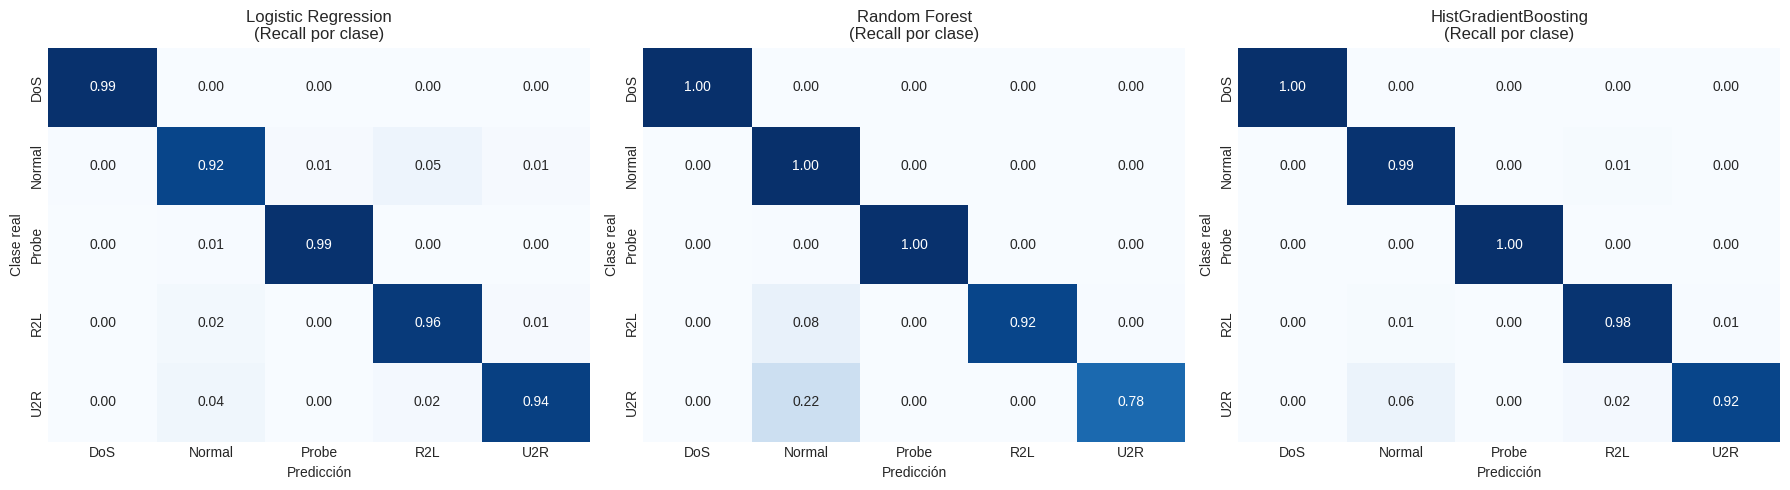

In [10]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, len(modelos_entrenados), figsize=(18, 5))
if len(modelos_entrenados) == 1:
    axes = [axes]

for ax, (nombre, y_pred) in zip(axes, modelos_entrenados.items()):
    cm = confusion_matrix(y_test, y_pred, labels=range(len(nombres_clases)))
    cm_norm = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    sns.heatmap(
        cm_norm,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        xticklabels=nombres_clases,
        yticklabels=nombres_clases,
        vmin=0,
        vmax=1,
        cbar=False,
        ax=ax
    )
    ax.set_title(f"{nombre}\n(Recall por clase)")
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Clase real")

plt.tight_layout()
plt.show()

## F. Interpretabilidad y Factores más Influyentes 

### F.1 Importancia de características (*Permutation Importance*)
Calculamos la importancia por permutación sobre el conjunto de prueba respecto al **F1 Macro** para identificar qué variables de tráfico, bytes o protocolo impulsan más la discriminación multiclase.

,Característica,Importancia media,Desv. est.
0,cat__service_other,0.08553,0.01773
1,num__dst_host_same_src_port_rate,0.01330,0.00075
2,cat__service_http,0.00919,0.00769
3,num__src_bytes,0.00569,0.00540
4,num__byte_ratio,0.00512,0.00373
5,num__log_src_bytes,0.00487,0.00446
6,num__dst_host_same_srv_rate,0.00252,0.00139
7,cat__service_ftp_data,0.00202,0.00036
8,num__log_duration,0.00162,0.00078
9,num__logged_in,0.00158,0.00093


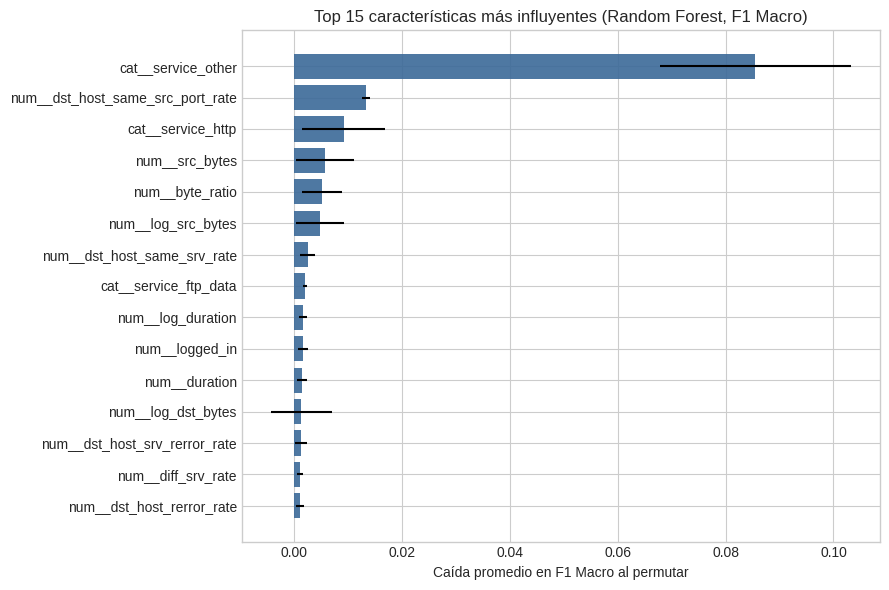

In [11]:
from sklearn.inspection import permutation_importance

nombres_features = preprocessor.get_feature_names_out()
estimador_base = modelos[mejor_modelo_nombre]

# Submuestra estratificada de test para cómputo ágil de permutation_importance
n_perm = min(6000, len(y_test))
idx_perm, _ = train_test_split(
    np.arange(len(y_test)), train_size=n_perm, random_state=42, stratify=y_test
)

perm = permutation_importance(
    estimador_base,
    X_test_proc[idx_perm],
    y_test[idx_perm],
    scoring="f1_macro",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

df_imp = pd.DataFrame({
    "Característica": nombres_features,
    "Importancia media": perm.importances_mean,
    "Desv. est.": perm.importances_std
}).sort_values(by="Importancia media", ascending=False).reset_index(drop=True)

display(df_imp.head(15).round(5))

top15 = df_imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top15["Característica"], top15["Importancia media"], xerr=top15["Desv. est."], color="#3B6998", alpha=0.9)
ax.set_title(f"Top 15 características más influyentes ({mejor_modelo_nombre}, F1 Macro)")
ax.set_xlabel("Caída promedio en F1 Macro al permutar")
plt.tight_layout()
plt.show()

## G. Conclusiones, Limitaciones y Próximos Pasos 

### G.1 Conclusiones principales
* **Desbalance severo entre familias de tráfico:** **Normal** y **DoS** concentran la gran mayoría de conexiones, mientras que **R2L** y **U2R** son clases muy minoritarias, por lo que el **F1 Macro** y la **Balanced Accuracy** reflejan mucho mejor el desempeño real que la *accuracy* global.
* **Señales clave de red:** Las variables vinculadas al volumen de bytes (`src_bytes`, `dst_bytes` y sus transformaciones logarítmicas), el protocolo/servicio/bandera de conexión y los patrones de conteo/tasas de error en ventanas temporales aportan un fuerte poder discriminativo frente a escaneos (**Probe**) e inundaciones (**DoS**).

### G.2 Limitaciones del enfoque actual
* **Dificultad en ataques sutiles de acceso/escalada:** Intrusiones como **U2R** y **R2L** suelen tener muy pocos ejemplos y comportamientos muy cercanos a sesiones legítimas, lo que limita el *recall* incluso con ponderación de clases.
* **Dependencia temporal / de flujo:** NSL-KDD resume flujos en estadísticas agregadas; en entornos reales de producción los ataques evolucionan con técnicas de evasión y cambios en el tráfico base (*concept drift*).

### G.3 Próximos pasos recomendados
* **Ajuste de umbrales y técnicas de remuestreo:** Combinar validación cruzada estratificada con ajuste de umbrales por clase o métodos de sobremuestreo/submuestreo en el *pipeline* de entrenamiento para elevar la detección de **R2L** y **U2R** sin disparar falsas alarmas en **Normal**.
* **Validación en datasets modernos y despliegue:** Contrastar los hallazgos en conjuntos de datos más recientes (como CIC-IDS2017 o CSE-CIC-IDS2018) y empaquetar el `preprocessor` junto al modelo ganador mediante `joblib` para inferencia en tiempo casi real.

In [12]:
# Ejemplo de empaquetado del pipeline completo (preprocesamiento + modelo final)
import joblib

pipeline_final = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", modelos[mejor_modelo_nombre])
])
pipeline_final.fit(X_train, y_train)
joblib.dump({"pipeline": pipeline_final, "label_encoder": le, "dropped_cols": cols_constantes}, "nsl_kdd_pipeline.joblib")
print("Pipeline guardado correctamente en 'nsl_kdd_pipeline.joblib'")

Pipeline guardado correctamente en 'nsl_kdd_pipeline.joblib'
